# assignment 2: exploratory charts

**research question:** did local food prices follow the 2022 world price spike, or did local grains rise for other reasons?

data: `clean/market_month_full.csv` (run `python3 clean_data.py` first). only mali, burkina faso and senegal, because niger has no local rice and chad has too few markets.

In [13]:
import matplotlib.pyplot as plt
import pandas as pd

data = pd.read_csv("../clean/market_month_full.csv")
foods = {"millet": "millet (local)", "rice_local": "local rice", "rice_imported": "imported rice"}
countries = {"MLI": "Mali", "BFA": "Burkina Faso", "SEN": "Senegal"}
prices = data[data.iso3.isin(countries) & data.food.isin(foods) & data.year.between(2019, 2024)]

# world cereal prices from fao, changed to 2019 = 100 so they're on the same scale as our price index
fao = data.drop_duplicates("month").set_index("month").fao_cereals_index.sort_index()
fao = fao / fao[fao.index.str[:4] == "2019"].mean() * 100
fao.index = pd.to_datetime(fao.index)
fao = fao["2019":"2024"]

## chart a: local prices vs world prices

median price index (2019 = 100) of all markets in the 3 countries, per food and month. the dashed line is the fao world cereals index.

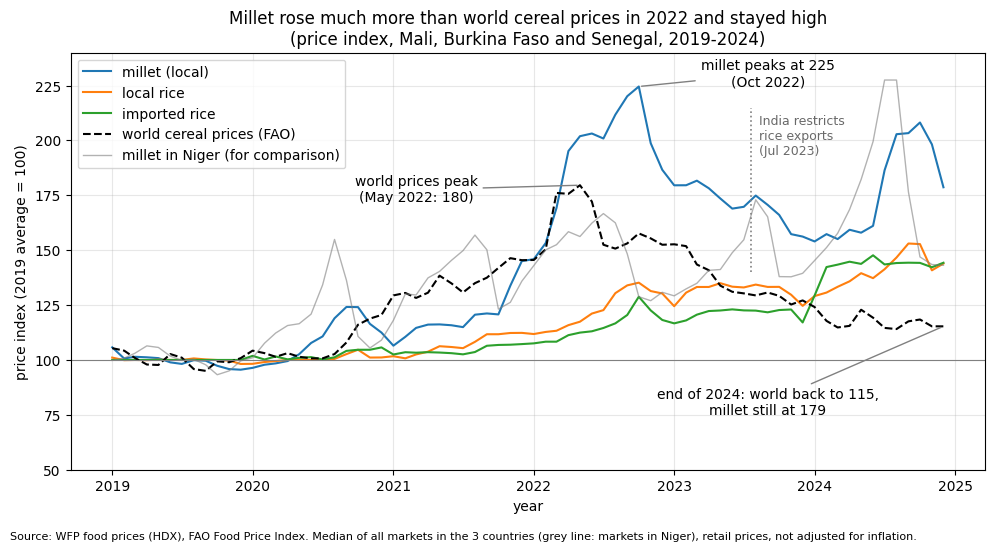

In [14]:
monthly = prices.groupby(["month", "food"]).price_index.median().unstack()
monthly.index = pd.to_datetime(monthly.index)
world_peak, millet_peak = fao.idxmax(), monthly.millet.idxmax()
end = monthly.index[-1]

plt.figure(figsize=(10, 5.5))
for food, label in foods.items():
    plt.plot(monthly[food], label=label)
plt.plot(fao, "k--", label="world cereal prices (FAO)")
# niger's millet as a light line in the background: there the rise started earlier (2021)
niger = data[(data.iso3 == "NER") & (data.food == "millet") & data.year.between(2019, 2024)]
niger = niger.groupby("month").price_index.median()
niger.index = pd.to_datetime(niger.index)
plt.plot(niger, color="grey", linewidth=1, alpha=0.6, label="millet in Niger (for comparison)")
plt.axhline(100, color="grey", linewidth=0.8)

# labels that tell the story: world peaks first, millet goes higher and stays high
line = dict(arrowstyle="-", color="grey")
plt.annotate(f"world prices peak\n({world_peak:%b %Y}: {fao.max():.0f})", (world_peak, fao.max()),
             xytext=(pd.Timestamp("2021-03-01"), 172), ha="center", arrowprops=line)
plt.annotate(f"millet peaks at {monthly.millet.max():.0f}\n({millet_peak:%b %Y})", (millet_peak, monthly.millet.max()),
             xytext=(pd.Timestamp("2023-09-01"), 225), ha="center", arrowprops=line)
plt.annotate(f"end of 2024: world back to {fao[end]:.0f},\nmillet still at {monthly.millet[end]:.0f}", (end, fao[end]),
             xytext=(pd.Timestamp("2023-09-01"), 75), ha="center", arrowprops=line)

# india stopped most rice exports in july 2023, imported rice jumps about half a year later
ban = pd.Timestamp("2023-07-20")
plt.vlines(ban, 140, 215, color="grey", linestyle=":", linewidth=1.2)
plt.text(ban + pd.Timedelta(days=20), 212, "India restricts\nrice exports\n(Jul 2023)", fontsize=9, color="dimgrey", va="top")

plt.title("Millet rose much more than world cereal prices in 2022 and stayed high\n"
          "(price index, Mali, Burkina Faso and Senegal, 2019-2024)")
plt.ylabel("price index (2019 average = 100)")
plt.xlabel("year")
plt.ylim(50, 240)
plt.legend(loc="upper left")
plt.grid(alpha=0.3)
plt.figtext(0.01, 0.01, "Source: WFP food prices (HDX), FAO Food Price Index. Median of all markets in the 3 countries (grey line: markets in Niger), "
            "retail prices, not adjusted for inflation.", fontsize=8)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig("chart_a_lines.png", dpi=300)
plt.show()

### design rationale (chart a)

*write 1-2 paragraphs: why a line chart, why an index instead of CFA francs, why the fao line is dashed and black, what the chart shows best and what it hides (e.g. differences between countries, the seasonal zigzag)*

## chart b: how much each food rose from 2021 to 2022

one row per country and food, plus world cereal prices in black for comparison. left dot = 2021, right dot = 2022 (yearly median of the price index). sorted by % change, biggest rise at the top.

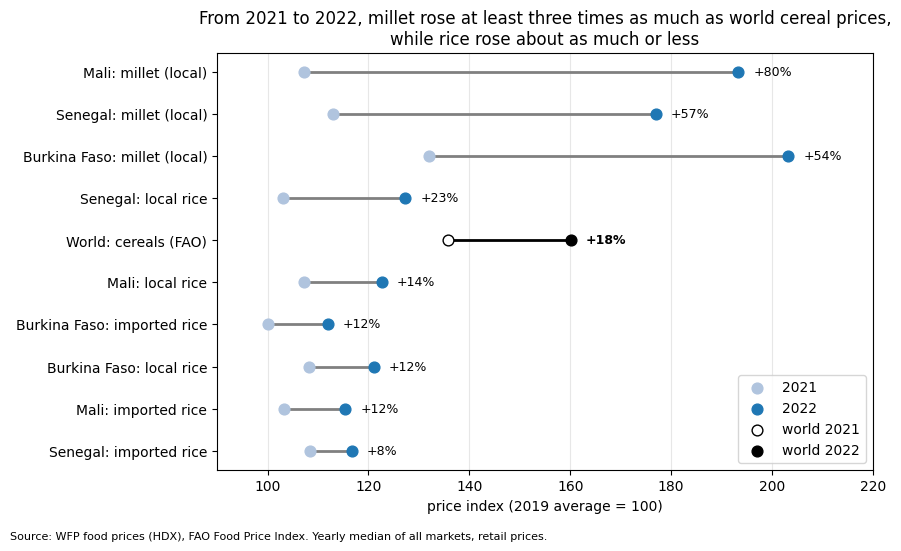

In [15]:
yearly = prices[prices.year.isin([2021, 2022])].groupby(["iso3", "food", "year"]).price_index.median().unstack()
yearly.index = [f"{countries[iso]}: {foods[food]}" for iso, food in yearly.index]
fao_yearly = fao.groupby(fao.index.year).mean()
yearly.loc["World: cereals (FAO)"] = [fao_yearly[2021], fao_yearly[2022]]
yearly["change"] = (yearly[2022] / yearly[2021] - 1) * 100
yearly = yearly.sort_values("change")  # biggest rise at the top
world = yearly.index == "World: cereals (FAO)"

plt.figure(figsize=(9, 5.5))
plt.hlines(yearly.index, yearly[2021], yearly[2022], color=["black" if w else "grey" for w in world], linewidth=2)
plt.scatter(yearly[2021][~world], yearly.index[~world], color="lightsteelblue", s=60, zorder=3, label="2021")
plt.scatter(yearly[2022][~world], yearly.index[~world], color="tab:blue", s=60, zorder=3, label="2022")
plt.scatter(yearly[2021][world], yearly.index[world], color="white", edgecolor="black", s=60, zorder=3, label="world 2021")
plt.scatter(yearly[2022][world], yearly.index[world], color="black", s=60, zorder=3, label="world 2022")
for name, row in yearly.iterrows():
    plt.text(row[2022] + 3, name, f"+{row.change:.0f}%", va="center", fontsize=9,
             fontweight="bold" if name == "World: cereals (FAO)" else "normal")
plt.title("From 2021 to 2022, millet rose at least three times as much as world cereal prices,\n"
          "while rice rose about as much or less")
plt.xlabel("price index (2019 average = 100)")
plt.xlim(90, 220)
plt.legend(loc="lower right")
plt.grid(axis="x", alpha=0.3)
plt.figtext(0.01, 0.01, "Source: WFP food prices (HDX), FAO Food Price Index. Yearly median of all markets, retail prices.", fontsize=8)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig("chart_b_dumbbell.png", dpi=300)
plt.show()

### design rationale (chart b)

*write 1-2 paragraphs: why a dumbbell chart, why it's sorted by the 2022 value, why the world row is included, what it shows best and what it hides (e.g. what happened after 2022, how many markets each row is based on)*

In [16]:
yearly.round(0)

year,2021,2022,change
Senegal: imported rice,108.0,117.0,8.0
Mali: imported rice,103.0,115.0,12.0
Burkina Faso: local rice,108.0,121.0,12.0
Burkina Faso: imported rice,100.0,112.0,12.0
Mali: local rice,107.0,123.0,14.0
World: cereals (FAO),136.0,160.0,18.0
Senegal: local rice,103.0,127.0,23.0
Burkina Faso: millet (local),132.0,203.0,54.0
Senegal: millet (local),113.0,177.0,57.0
Mali: millet (local),107.0,193.0,80.0
